# Stage 2: Return generating models

A return generating model explains why returns move. Instead of treating each stock separately, it
splits a stock's return into a part driven by common factors and a part unique to the stock:

r_i − r_f = α_i + β_i × F + ε_i

Markowitz optimization needs two inputs: expected returns and a covariance matrix. For 25 stocks the
covariance matrix alone has 325 separate numbers. A factor model replaces most of them with a few
betas, which cuts estimation error.

This stage answers three questions, using **estimation months only**:

1. How much of each stock's risk is market-wide, and how much is stock-specific?
2. Do more factors explain returns better?
3. Which estimates of covariance and expected return would have worked best out of sample?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import models
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, SERIES_1, SERIES_2, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
sectors = data.universe.set_index("symbol")["sector"]

excess_all = ret.select_period(data.excess, data.periods, "estimation")
excess = excess_all[stocks]
market = excess_all[config.market_proxy]
factors = data.factors.loc[excess.index]
factors_nifty = factors.assign(MKT_RF=market)   # same style factors, Nifty as the market
long_factors = data.factors_long.loc[:excess.index.max()]
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12
print(f"{len(excess)} months; long factor history {long_factors.index.min():%b %Y} onward")

153 months; long factor history Nov 1993 onward


## 1. The single-index model

r_i − r_f = α_i + β_i (r_m − r_f) + ε_i

- **β** measures sensitivity to the market.
- **R²** is the share of variance the market explains. The rest is stock-specific.
- **α** is the average return left unexplained.

Total variance splits into σ²_i = β²_i σ²_m + σ²(ε_i). Only the first part is risk that
diversification cannot remove.

In [2]:
single = models.fit_factor_model(excess, market.to_frame("MKT"))
table = pd.DataFrame({
    "sector": sectors,
    "beta": single.betas["MKT"],
    "r_squared": single.r_squared,
    "alpha_annual": single.alpha * 12,
    "alpha_t": single.alpha_t,
    "residual_vol": np.sqrt(single.residual_variance * 12),
}).sort_values("beta")
table.round(2)

,sector,beta,r_squared,alpha_annual,alpha_t,residual_vol
DRREDDY,Healthcare,0.25,0.03,0.06,0.89,0.25
HINDUNILVR,FMCG,0.29,0.05,0.13,2.60,0.21
NESTLEIND,FMCG,0.43,0.13,0.10,2.01,0.18
TCS,Information Technology,0.47,0.12,0.09,1.97,0.21
SUNPHARMA,Healthcare,0.54,0.10,0.08,1.20,0.26
INFY,Information Technology,0.61,0.15,0.06,1.00,0.25
HCLTECH,Information Technology,0.64,0.16,0.14,2.36,0.24
ITC,FMCG,0.66,0.27,0.06,1.15,0.18
ASIANPAINT,Consumer,0.72,0.22,0.13,2.42,0.23
BHARTIARTL,Telecom,0.79,0.22,0.03,0.38,0.24


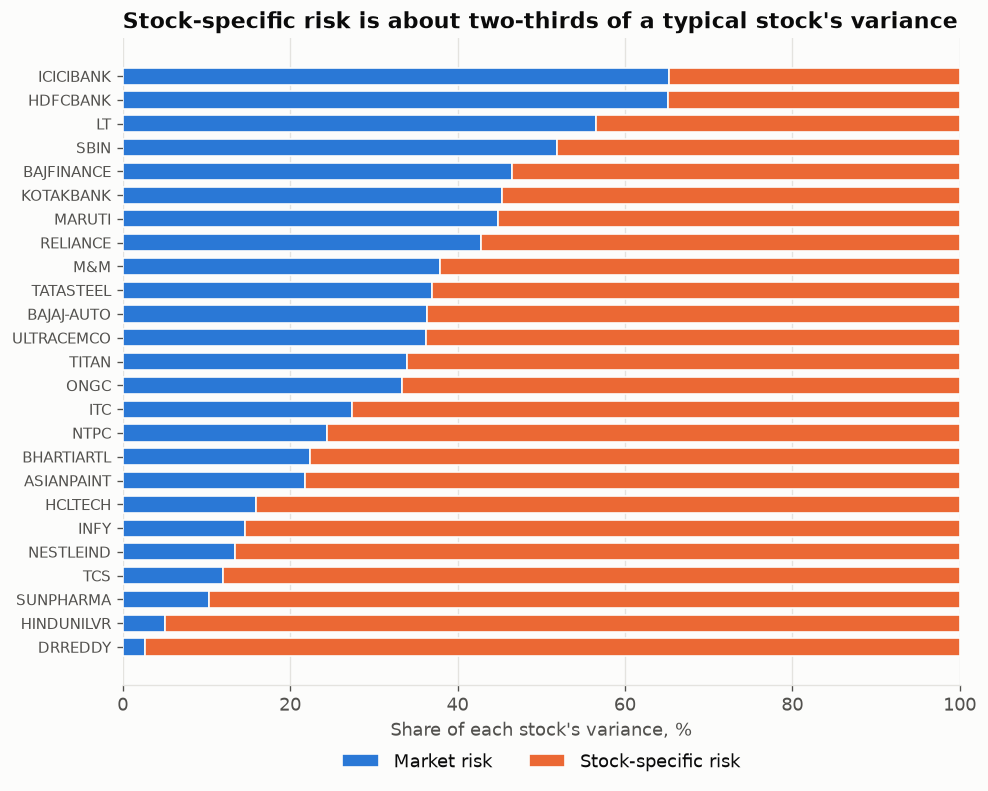

,value
Average beta,0.938
Average R²,0.321
Stocks with positive alpha,22.000
Stocks with alpha t-stat above 2,7.000
Average annual alpha,0.074


In [3]:
order = single.r_squared.sort_values().index
fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.barh(order, single.r_squared[order] * 100, color=SERIES_1, height=0.72,
        edgecolor=SURFACE, linewidth=1, label="Market risk")
ax.barh(order, (1 - single.r_squared[order]) * 100, left=single.r_squared[order] * 100,
        color=SERIES_2, height=0.72, edgecolor=SURFACE, linewidth=1, label="Stock-specific risk")
ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=9)
ax.set_xlabel("Share of each stock's variance, %")
ax.set_title("Stock-specific risk is about two-thirds of a typical stock's variance")
ax.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIGURES / "02_risk_decomposition.png")
plt.show()

pd.Series({
    "Average beta": single.betas["MKT"].mean(),
    "Average R²": single.r_squared.mean(),
    "Stocks with positive alpha": (single.alpha > 0).sum(),
    "Stocks with alpha t-stat above 2": (single.alpha_t > 2).sum(),
    "Average annual alpha": single.alpha.mean() * 12,
}).round(3).to_frame("value")

**The alphas should not be taken as skill.** In a fair sample, alphas would average near zero
once weighted by market value. Here almost all are positive because the sample contains only
survivors and the market proxy misses some early dividends. Stage 8 returns to this.

## 2. Does the model's key assumption hold?

The single-index covariance assumes residuals are uncorrelated: stocks are linked only through the
market. If that were true, residual correlations would be close to zero.

In [4]:
residual_check = pd.DataFrame({
    "Single index": models.average_correlation_by_group(single.residuals, sectors),
}).rename(index={"same_group": "Same sector", "different_group": "Different sector"})
banks = sectors.index[sectors == "Financial Services"]
print(f"Largest residual correlation in Financial Services: "
      f"{single.residuals[banks].corr().where(lambda c: c < 0.999).max().max():.2f}")
residual_check.round(3)

Largest residual correlation in Financial Services: 0.44


,Single index
Same sector,0.245
Different sector,-0.035


**The assumption fails within sectors.** Stocks in the same sector still move together after
removing the market, but across sectors the link is close to zero. Section 4 tests whether this
matters in practice.

## 3. Multi-factor models

The arbitrage pricing theory (APT) allows several priced sources of risk. This uses the Indian
factors published by IIMA:

| Factor | Long position | Short position |
|---|---|---|
| **MKT** | Market | T-bills |
| **SMB** | Small companies | Large companies |
| **HML** | Cheap (high book-to-market) | Expensive (low book-to-market) |
| **WML** | Recent winners | Recent losers |

IIMA's market is broader than the Nifty 50. Our stocks are large caps, so the Nifty is a better fit,
and the regressions below use Nifty excess returns with IIMA's three style factors.

In [5]:
four = models.fit_factor_model(excess, factors_nifty)
premia = pd.DataFrame({
    "long_run_mean": long_factors.mean() * 12,
    "standard_error": long_factors.std() * 12 / np.sqrt(len(long_factors)),
    "estimation_mean": factors.mean() * 12,
})
premia["t_stat"] = premia["long_run_mean"] / premia["standard_error"]
print(f"Long-run sample: {len(long_factors)} months. Average R²: single index "
      f"{single.r_squared.mean():.3f}, four factor {four.r_squared.mean():.3f}")
print("Average factor betas:", four.betas.mean().round(2).to_dict())
premia.round(3)

Long-run sample: 359 months. Average R²: single index 0.321, four factor 0.376
Average factor betas: {'SMB': 0.01, 'HML': 0.03, 'WML': -0.0, 'MKT_RF': 0.92}


,long_run_mean,standard_error,estimation_mean,t_stat
SMB,-0.026,0.031,0.018,-0.841
HML,0.082,0.038,0.066,2.146
WML,0.137,0.046,0.153,2.976
MKT_RF,0.085,0.046,0.070,1.842


In [6]:
four.betas.assign(r_squared=four.r_squared).sort_values("MKT_RF").round(2)

,SMB,HML,WML,MKT_RF,r_squared
DRREDDY,-0.04,0.00,0.19,0.36,0.04
HINDUNILVR,-0.17,-0.14,0.15,0.47,0.10
NTPC,-0.03,0.55,-0.15,0.47,0.37
SUNPHARMA,-0.13,0.14,0.18,0.58,0.12
NESTLEIND,0.12,-0.19,0.19,0.60,0.20
ITC,-0.08,-0.08,-0.02,0.70,0.28
BHARTIARTL,-0.28,0.30,0.07,0.72,0.27
ONGC,-0.21,0.66,0.01,0.75,0.46
TCS,-0.12,-0.45,0.25,0.84,0.30
BAJAJ-AUTO,0.03,0.06,-0.02,0.88,0.37


The extra factors add little for these large caps. Note the wide standard errors too: even with
30 years of data, the market premium is known only to within several percentage points.

## 4. Which covariance estimate works best?

In-sample fit cannot settle this, since the sample covariance always fits its own data best. The
fair test works as follows:

1. Estimate the covariance matrix on a trailing window.
2. Build the minimum variance portfolio from it.
3. Hold it for the next year and measure the realized volatility.
4. Roll forward and repeat.

A better risk estimate produces a lower realized volatility. This all happens inside the estimation
period, so the holdout stays untouched.

In [7]:
def covariance_row(window, step):
    paths = models.walk_forward_covariance(excess, market, factors_nifty, sectors, window, step)
    broad = models.walk_forward_covariance(excess, market, factors, sectors, window, step)
    vols = paths.std() * np.sqrt(12) * 100
    vols = vols.rename({"Four factor": "Four factor, Nifty market"})
    vols["Four factor, broad market"] = broad["Four factor"].std() * np.sqrt(12) * 100
    vols["Equal weight (no estimate)"] = excess.loc[paths.index].mean(axis=1).std() * np.sqrt(12) * 100
    vols["months_tested"] = len(paths)
    return vols

settings = [(36, 12), (48, 12), (60, 12), (84, 12), (60, 6), (60, 3)]
robustness = pd.DataFrame({f"{w}m window, refit {s}m": covariance_row(w, s) for w, s in settings}).T
robustness.round(2).T

,"36m window, refit 12m","48m window, refit 12m","60m window, refit 12m","84m window, refit 12m","60m window, refit 6m","60m window, refit 3m"
Sample,24.61,16.42,17.36,18.05,16.34,16.19
Single index,14.19,14.60,14.85,17.17,14.54,14.21
Single index + sectors,14.40,14.99,14.95,16.97,14.37,14.02
"Four factor, Nifty market",13.78,14.20,14.55,16.67,14.24,13.91
Ledoit-Wolf,14.35,14.46,15.40,17.18,14.67,14.47
"Four factor, broad market",14.46,14.59,15.18,17.03,14.77,14.46
Equal weight (no estimate),16.03,16.30,16.81,18.23,16.37,16.21
months_tested,108.00,96.00,84.00,60.00,90.00,93.00


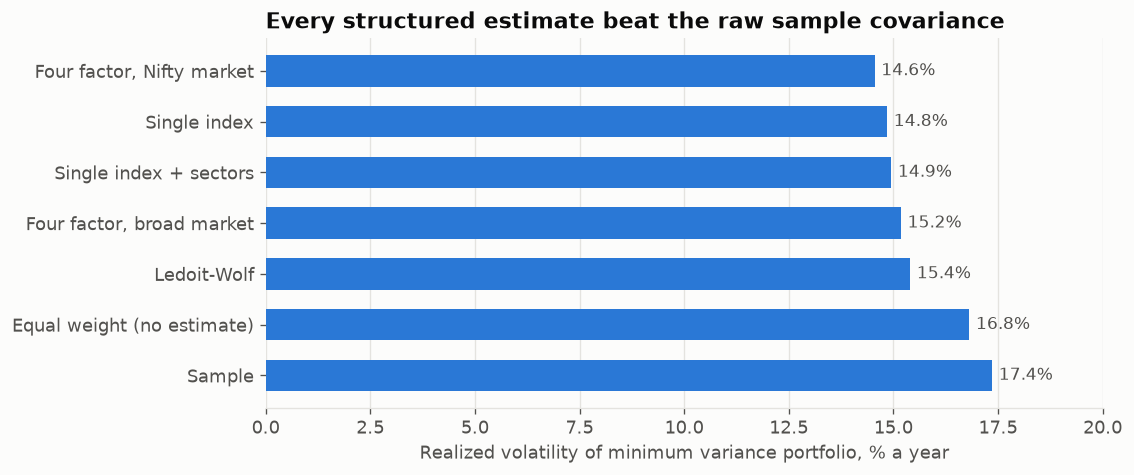

Sample minus worst structured estimate: 0.87 to 10.15 points
Lowest in each test: {'Four factor, Nifty market': 6}


In [8]:
base = robustness.loc["60m window, refit 12m"].drop("months_tested").sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
bars = ax.barh(base.index, base, color=SERIES_1, height=0.62)
ax.bar_label(bars, fmt="%.1f%%", padding=4, color=MUTED, fontsize=10)
ax.set_xlim(0, 20)
ax.set_xlabel("Realized volatility of minimum variance portfolio, % a year")
ax.set_title("Every structured estimate beat the raw sample covariance")
fig.savefig(FIGURES / "02_covariance_test.png")
plt.show()
sample_gap = (robustness["Sample"] - robustness.drop(columns=["Sample", "Equal weight (no estimate)", "months_tested"]).max(axis=1))
print(f"Sample minus worst structured estimate: {sample_gap.min():.2f} to {sample_gap.max():.2f} points")
print(f"Lowest in each test: {robustness.drop(columns=['months_tested']).idxmin(axis=1).value_counts().to_dict()}")

Standard error on each volatility here is roughly 1 point, so small gaps between structured
models are mostly noise. Comparing several variants also flatters whichever one wins. The stable
conclusion is that the raw sample covariance is the wrong choice.

**Chosen for practical use: single index.** Four-factor with the Nifty market scored lowest in every
test, but only by 0.3 to 0.5 points, and IIMA's factors end in December 2025. A model needing them could not run on
recent months in Stage 10 or in the live tool. The single index needs only prices.

## 5. Which expected return estimate works best?

The test here is the same idea. Each forecast uses only earlier data, and it is compared with each
stock's realized return over the next year. Six candidates:

| Estimator | Expected excess return |
|---|---|
| Historical mean | The stock's own trailing average |
| Grand mean | The same average for every stock |
| Shrunk mean | Halfway between those two |
| CAPM | β × long-run market premium |
| Blend | Halfway between historical mean and CAPM |
| Four factor | Factor betas × long-run factor premia |

`rmse` is the forecast error in annual terms, and `rank_corr` is how well the forecast ordered the
stocks (0 means no ability).

In [9]:
frames = {}
for window, step in [(36, 12), (60, 12), (84, 12)]:
    scored = models.walk_forward_returns(excess, market, factors_nifty, data.factors_long, window, step)
    frames[f"{window}m window"] = scored.groupby("estimator")[["rmse", "rank_corr", "bias"]].mean()
    frames[f"{window}m window"]["forecasts"] = scored["origin"].nunique()
pd.concat(frames, axis=1).round(3)

36m window                            60m window            \
                      rmse rank_corr   bias forecasts       rmse rank_corr   
estimator                                                                    
Blend                0.276     0.057 -0.042         9      0.247     0.053   
CAPM                 0.268     0.166 -0.065         9      0.244     0.187   
Four factor          0.279    -0.013 -0.062         9      0.251     0.021   
Grand mean           0.278       NaN -0.018         9      0.246       NaN   
Historical mean      0.304     0.023 -0.018         9      0.265     0.028   
Shrunk mean          0.282     0.023 -0.018         9      0.248     0.028   

                                 84m window                             
                  bias forecasts       rmse rank_corr   bias forecasts  
estimator                                                               
Blend           -0.051         7      0.237     0.037 -0.036         5  
CAPM            -0.073         7      0.242     0.003 -0.057         5  
Four factor     -0.072         7      0.238     0.088 -0.056         5  
Grand mean      -0.029         7      0.232       NaN -0.014         5  
Historical mean -0.029         7      0.245     0.044 -0.014         5  
Shrunk mean     -0.029         7      0.233     0.044 -0.014         5

**No estimator forecasts well.** Errors of about 25 points dwarf the differences between methods,
because one year of a stock's return is mostly noise. With so few independent test years, the
ranking between the better methods cannot be trusted. Two points do hold across windows:

- **The raw historical mean is the worst or close to it.** It is what the textbook Markowitz model
  uses, and it is the input we should trust least.
- **Forecasts ran below realized returns.** Survivorship is the likely reason, since these stocks are
  winners that outperformed what any model expected.

## 6. Inputs for the next stages

Stages 3 to 5 will carry two sets of inputs side by side, so the effect of estimation error stays
visible:

| Set | Expected return | Covariance | Purpose |
|---|---|---|---|
| **Textbook** | Historical mean | Sample | The classic Markowitz calculation |
| **Practical** | 50% historical, 50% CAPM | Single index | More robust, for real use |

CAPM alone is not used because it says nothing beyond beta, and a portfolio optimized on it would
just rebuild the market. The blend keeps some stock-specific information while pulling back the
extremes. The market premium comes from the 30-year IIMA history.

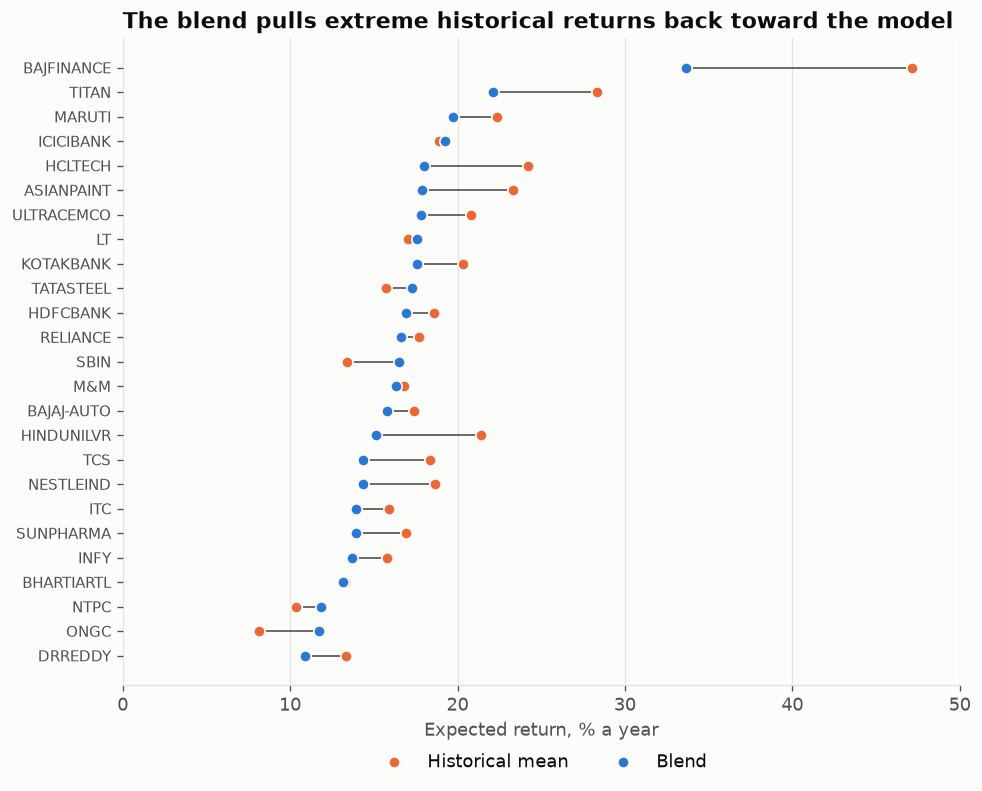

,value
Market premium used (% a year),8.5
Risk-free rate (% a year),6.4
Historical: highest minus lowest stock (points),39.0
Blend: highest minus lowest stock (points),22.7
Sample covariance condition number,77.3
Single-index covariance condition number,43.7


In [10]:
premium = long_factors["MKT_RF"].mean()
text_mean, text_cov = models.textbook_inputs(excess)
prac_mean, prac_cov = models.practical_inputs(excess, market, premium)

expected = pd.DataFrame({
    "Historical": text_mean * 12 + RISK_FREE,
    "CAPM": single.betas["MKT"] * premium * 12 + RISK_FREE,
    "Blend": prac_mean * 12 + RISK_FREE,
}).sort_values("Blend")

fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
positions = np.arange(len(expected))
ax.hlines(positions, expected["Historical"] * 100, expected["Blend"] * 100, color=MUTED, linewidth=1)
ax.scatter(expected["Historical"] * 100, positions, s=46, color=SERIES_2, edgecolor=SURFACE,
           zorder=3, label="Historical mean")
ax.scatter(expected["Blend"] * 100, positions, s=46, color=SERIES_1, edgecolor=SURFACE,
           zorder=3, label="Blend")
ax.set_yticks(positions, expected.index, fontsize=9)
ax.set_xlim(0, 50)
ax.set_xlabel("Expected return, % a year")
ax.set_title("The blend pulls extreme historical returns back toward the model")
ax.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIGURES / "02_expected_returns.png")
plt.show()

pd.Series({
    "Market premium used (% a year)": premium * 1200,
    "Risk-free rate (% a year)": RISK_FREE * 100,
    "Historical: highest minus lowest stock (points)": (expected["Historical"].max() - expected["Historical"].min()) * 100,
    "Blend: highest minus lowest stock (points)": (expected["Blend"].max() - expected["Blend"].min()) * 100,
    "Sample covariance condition number": np.linalg.cond(text_cov),
    "Single-index covariance condition number": np.linalg.cond(prac_cov),
}).round(1).to_frame("value")

## Stage 2 conclusions

1. **Most single-stock risk is diversifiable:** the market explains about a third of a typical
   stock's variance. Theory says only that third should earn a reward.
2. **Betas range widely:** from about 0.25 (Dr. Reddy's) to 1.6 (Bajaj Finance).
3. **More factors add little here:** four factors lift average R² only slightly above the single
   index for these large caps.
4. **Sectors remain linked:** residuals stay correlated within sectors, which the single index ignores.
   This has little effect on portfolio results so far, but it supports sector caps in Stage 4.
5. **Do not use the raw sample covariance:** every structured estimate beat it out of sample.
6. **Nothing forecasts stock returns well:** the raw historical mean is the weakest input, so
   estimates should be shrunk and portfolios constrained.

Survivorship bias and the proxy's missing early dividends both inflate the alphas above.